In [ ]:
from pathlib import Path
import shutil
import tarfile

from google.colab import drive

drive.mount("/content/drive")

bundle = Path("/content/digikala_inputs.tar.gz")
shutil.copyfile(
    "/content/drive/MyDrive/digikala-project-3/digikala_inputs.tar.gz",
    bundle,
)
with tarfile.open(bundle, "r:gz") as archive:
    archive.extractall("/content", filter="data")

print("Baseline inputs restored.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Baseline inputs restored.


In [ ]:
%pip -q install "transformers>=4.57" duckdb

import json
from pathlib import Path

import duckdb
import numpy as np
import torch
import transformers
from transformers import AutoTokenizer

from normalize_persian import normalize_text

if not torch.cuda.is_available():
    raise RuntimeError("Select T4 GPU in Runtime > Change runtime type.")

MODEL_ID = "HooshvareLab/bert-fa-base-uncased"
MODEL_REVISION = "a04aa40c97bcdde570ae11986a534542c2995a62"
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, use_fast=True,
)

with duckdb.connect() as db:
    sample = db.execute("""
        SELECT body, recommendation_status, rating_band
        FROM read_csv('/content/digikala_splits/train_supervised.csv',
                      header = true, all_varchar = true)
        ORDER BY substr(sha256('2026|' || id), 1, 16), id
        LIMIT 20000
    """).df()

lengths = []
for start in range(0, len(sample), 512):
    texts = [normalize_text(text) for text in sample["body"].iloc[start:start + 512]]
    encoded = tokenizer(texts, padding=False, truncation=False, verbose=False)
    lengths.extend(len(ids) for ids in encoded["input_ids"])

sample["tokens"] = lengths
limits = [64, 96, 128]
for limit in limits:
    sample[f"over_{limit}"] = sample["tokens"].gt(limit)

columns = [f"over_{limit}" for limit in limits]
overall = (100 * sample[columns].mean()).round(2)
p50, p95, p99 = np.percentile(lengths, [50, 95, 99]).tolist()
gpu = torch.cuda.get_device_properties(0)

print(f"GPU: {gpu.name} | VRAM: {gpu.total_memory / 2**30:.1f} GiB")
print(f"Tokenizer: {type(tokenizer).__name__} | Transformers: {transformers.__version__}")
print(f"Training sample: {len(sample):,} | p50={p50:g}, p95={p95:g}, p99={p99:g} tokens")
print("\nText truncated at each limit (%)")
print(overall.to_string())

by_class = {}
for target in ["recommendation_status", "rating_band"]:
    table = (100 * sample.groupby(target)[columns].mean()).round(2)
    by_class[target] = table.to_dict(orient="index")
    print(f"\n{target} (% truncated)")
    print(table.to_string())

report = {
    "model": MODEL_ID,
    "revision": MODEL_REVISION,
    "license": "Apache-2.0",
    "tokenizer": type(tokenizer).__name__,
    "transformers_version": transformers.__version__,
    "torch_version": str(torch.__version__),
    "gpu": gpu.name,
    "sample_rows": len(sample),
    "sample_rule": "First 20000 supervised train rows ordered by SHA-256('2026|' + id) prefix, then id",
    "token_length_percentiles": {"p50": p50, "p95": p95, "p99": p99},
    "truncation_pct": overall.to_dict(),
    "truncation_pct_by_class": by_class,
}

report_path = Path(
    "/content/drive/MyDrive/digikala-project-3/reports/tokenizer_profile.json"
)
report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
print(f"\nSaved: {report_path.name}")

config.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

GPU: Tesla T4 | VRAM: 14.6 GiB
Tokenizer: BertTokenizer | Transformers: 5.22.1
Training sample: 20,000 | p50=9, p95=39, p99=72 tokens

Text truncated at each limit (%)
over_64     1.30
over_96     0.43
over_128    0.16

recommendation_status (% truncated)
                       over_64  over_96  over_128
recommendation_status                            
no_idea                   1.82     0.75      0.32
not_recommended           3.36     0.99      0.33
recommended               0.95     0.28      0.11

rating_band (% truncated)
             over_64  over_96  over_128
rating_band                            
high            0.99     0.37      0.12
low             2.05     0.59      0.31
medium          1.69     0.49      0.15

Saved: tokenizer_profile.json


In [ ]:
%%writefile /content/digikala_transformer.py

from torch import nn
from torch.nn import functional as F

REC_LABELS = {"recommended": 0, "not_recommended": 1, "no_idea": 2}
BAND_LABELS = {"low": 0, "medium": 1, "high": 2}
IGNORE_INDEX = -100

class DigikalaTransformer(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.encoder.requires_grad_(False)
        self.encoder.encoder.layer[-1].requires_grad_(True)

        hidden_size = encoder.config.hidden_size
        self.dropout = nn.Dropout(encoder.config.hidden_dropout_prob)
        self.recommendation_head = nn.Linear(hidden_size, len(REC_LABELS))
        self.rating_head = nn.Linear(hidden_size, len(BAND_LABELS))

    def forward(self, **inputs):
        cls = self.encoder(**inputs).last_hidden_state[:, 0]
        features = self.dropout(cls)
        return self.recommendation_head(features), self.rating_head(features)

def masked_cross_entropy(logits, targets, weights=None):
    valid = targets.ne(IGNORE_INDEX)
    losses = F.cross_entropy(
        logits, targets, weight=weights, ignore_index=IGNORE_INDEX,
        reduction="none",
    )
    denominator = valid.sum()
    if weights is not None:
        denominator = (weights[targets.clamp_min(0)] * valid).sum()
    return losses.sum() / denominator.clamp_min(1e-12)

Writing /content/digikala_transformer.py


In [ ]:
from time import perf_counter

import torch
from transformers import AutoModel

from digikala_transformer import (
    BAND_LABELS, IGNORE_INDEX, REC_LABELS,
    DigikalaTransformer, masked_cross_entropy,
)

MAX_LENGTH = 96
BATCH_SIZE = 64
PILOT_STEPS = 8

torch.manual_seed(2026)
encoder = AutoModel.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, add_pooling_layer=False,
    use_safetensors=False, weights_only=True, trust_remote_code=False,
)
model = DigikalaTransformer(encoder).to("cuda").train()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert masked_cross_entropy(
    torch.zeros(2, 3), torch.full((2,), IGNORE_INDEX)
).item() == 0.0

def pilot_step(start):
    rows = sample.iloc[start:start + BATCH_SIZE]
    texts = [normalize_text(text) for text in rows["body"]]
    inputs = tokenizer(
        texts, truncation=True, max_length=MAX_LENGTH,
        padding=True, pad_to_multiple_of=8, return_tensors="pt",
    ).to("cuda")
    recommendation = torch.tensor(
        rows["recommendation_status"].map(REC_LABELS).fillna(IGNORE_INDEX).tolist(),
        dtype=torch.long, device="cuda",
    )
    band = torch.tensor(
        rows["rating_band"].map(BAND_LABELS).fillna(IGNORE_INDEX).tolist(),
        dtype=torch.long, device="cuda",
    )

    model.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda", dtype=torch.float16):
        rec_logits, band_logits = model(**inputs)
        loss = (
            masked_cross_entropy(rec_logits, recommendation)
            + masked_cross_entropy(band_logits, band)
        )
    loss.backward()
    return loss.detach()

pilot_step(0)
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

started = perf_counter()
losses = torch.stack([pilot_step(i * BATCH_SIZE) for i in range(1, PILOT_STEPS + 1)])
torch.cuda.synchronize()
elapsed = perf_counter() - started

assert torch.isfinite(losses).all().item()
for head in [model.recommendation_head, model.rating_head]:
    assert head.weight.grad is not None and torch.isfinite(head.weight.grad).all().item()

model.zero_grad(set_to_none=True)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,} ({trainable_params / total_params:.2%})")
print(f"Batch size: {BATCH_SIZE} | Max length: {MAX_LENGTH}")
print(f"Mean pilot loss: {losses.mean().item():.4f}")
print(f"Peak GPU memory allocated: {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB")
print(f"Pilot speed: {PILOT_STEPS * BATCH_SIZE / elapsed:,.0f} reviews/second")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

Total parameters: 162,255,366
Trainable parameters: 7,092,486 (4.37%)
Batch size: 64 | Max length: 96
Mean pilot loss: 2.4130
Peak GPU memory allocated: 0.91 GiB
Pilot speed: 448 reviews/second


In [ ]:
%%writefile /content/digikala_training.py

import numpy as np
import torch
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from digikala_transformer import BAND_LABELS, IGNORE_INDEX, REC_LABELS, masked_cross_entropy
from normalize_persian import normalize_text

def make_loader(frame, tokenizer, max_length, batch_size, *, shuffle=False, seed=2026):
    bodies = frame["body"].map(normalize_text)
    recommendation = frame["recommendation_status"].map(REC_LABELS).fillna(IGNORE_INDEX)
    rating = frame["rating_band"].map(BAND_LABELS).fillna(IGNORE_INDEX)
    rows = list(zip(bodies, recommendation.astype(int), rating.astype(int)))

    def collate(batch):
        text, rec, band = zip(*batch)
        inputs = tokenizer(
            list(text), truncation=True, max_length=max_length,
            padding=True, pad_to_multiple_of=8, return_tensors="pt",
        )
        return inputs, torch.tensor(rec, dtype=torch.long), torch.tensor(band, dtype=torch.long)

    return DataLoader(
        rows, batch_size=batch_size, shuffle=shuffle, collate_fn=collate,
        generator=torch.Generator().manual_seed(seed),
    )

def run_epoch(model, loader, weights, *, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss = torch.zeros((), device="cuda")
    actual = [[], []]
    predicted = [[], []]

    for inputs, rec, band in tqdm(loader, desc="Train" if training else "Validation"):
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training), torch.amp.autocast("cuda", dtype=torch.float16):
            logits = model(**inputs.to("cuda"))
            loss = sum(
                masked_cross_entropy(scores, target.to("cuda"), weight)
                for scores, target, weight in zip(logits, (rec, band), weights)
            )

        if training:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], max_norm=1.0
            )
            scaler.step(optimizer)
            scaler.update()
        else:
            for head, (scores, target) in enumerate(zip(logits, (rec, band))):
                valid = target.ne(IGNORE_INDEX)
                actual[head].append(target[valid].numpy())
                predicted[head].append(scores.argmax(dim=1).cpu()[valid].numpy())

        total_loss += loss.detach()

    result = {"loss": float(total_loss.item() / len(loader))}
    if not training:
        for head, name in enumerate(("recommendation_macro_f1", "rating_macro_f1")):
            result[name] = float(f1_score(
                np.concatenate(actual[head]), np.concatenate(predicted[head]),
                labels=[0, 1, 2], average="macro", zero_division=0,
            ))
    return result

Overwriting /content/digikala_training.py


In [ ]:
import json
import math
import shutil
from pathlib import Path
from time import perf_counter

import duckdb
import torch

from digikala_training import make_loader, run_epoch

SEED = 2026
TRAIN_ROWS = 120_000
VALIDATION_ROWS = 20_000
MAX_EPOCHS = 3
PATIENCE = 1
ENCODER_LR = 2e-5
HEAD_LR = 2e-4

project_drive = Path("/content/drive/MyDrive/digikala-project-3")
checkpoint_dir = project_drive / "artifacts" / "parsbert_supervised"
checkpoint_dir.mkdir(parents=True, exist_ok=True)
latest_path = checkpoint_dir / "latest.pt"
best_path = checkpoint_dir / "best.pt"
report_path = project_drive / "reports" / "parsbert_supervised_training.json"

sample_rule = "Sort by the first 16 hex digits of SHA-256('2026|' + id), then by id."
with duckdb.connect(config={"memory_limit": "3GB", "threads": "2"}) as db:
    train_frame, validation_frame = [
        db.execute("""
            SELECT id, body, recommendation_status, rating_band
            FROM read_csv(?, header=true, all_varchar=true)
            ORDER BY substr(sha256('2026|' || id), 1, 16), id
            LIMIT ?
        """, [f"/content/digikala_splits/{name}.csv", size]).df()
        for name, size in [
            ("train_supervised", TRAIN_ROWS), ("validation", VALIDATION_ROWS)
        ]
    ]

def balanced_weights(values, labels):
    counts = values.value_counts().reindex(list(labels), fill_value=0)
    assert (counts > 0).all()
    return torch.tensor(
        (counts.sum() / (len(counts) * counts)).tolist(),
        dtype=torch.float32, device="cuda",
    )

weights = (
    balanced_weights(train_frame["recommendation_status"], REC_LABELS),
    balanced_weights(train_frame["rating_band"], BAND_LABELS),
)
validation_loader = make_loader(validation_frame, tokenizer, MAX_LENGTH, BATCH_SIZE)

settings = {
    "model": MODEL_ID,
    "revision": MODEL_REVISION,
    "seed": SEED,
    "sample_rule": sample_rule,
    "train_rows": len(train_frame),
    "validation_rows_for_checkpoint_selection": len(validation_frame),
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation": 1,
    "encoder_lr": ENCODER_LR,
    "head_lr": HEAD_LR,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "checkpoint_metric": "Mean of recommendation and rating-band validation macro F1",
    "total_parameters": sum(p.numel() for p in model.parameters()),
    "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
    "recommendation_weights": weights[0].tolist(),
    "rating_band_weights": weights[1].tolist(),
}

optimizer = torch.optim.AdamW([
    {"params": model.encoder.encoder.layer[-1].parameters(), "lr": ENCODER_LR},
    {"params": list(model.recommendation_head.parameters()) +
               list(model.rating_head.parameters()), "lr": HEAD_LR},
], weight_decay=0.01)
scaler = torch.amp.GradScaler("cuda")

def save_checkpoint(payload, path):
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)

history = []
best_score = -1.0
best_epoch = 0
stale_epochs = 0

if latest_path.exists():
    progress = torch.load(latest_path, map_location="cpu", weights_only=True)
    if progress["settings"] != settings:
        raise ValueError("Saved checkpoint uses different training settings.")
    model.load_state_dict(progress["parameters"], strict=False)
    optimizer.load_state_dict(progress["optimizer"])
    scaler.load_state_dict(progress["scaler"])
    history = progress["history"]
    best_score = progress["best_score"]
    best_epoch = progress["best_epoch"]
    stale_epochs = progress["stale_epochs"]
    del progress

print(f"Train: {len(train_frame):,} | Validation for checkpoint selection: {len(validation_frame):,}")
print(f"Resuming after epoch {len(history)}", flush=True)

for epoch in range(len(history) + 1, MAX_EPOCHS + 1):
    if stale_epochs >= PATIENCE:
        break

    torch.manual_seed(SEED + epoch)
    train_loader = make_loader(
        train_frame, tokenizer, MAX_LENGTH, BATCH_SIZE, shuffle=True, seed=SEED + epoch
    )
    started = perf_counter()
    train_metrics = run_epoch(model, train_loader, weights, optimizer=optimizer, scaler=scaler)
    validation_metrics = run_epoch(model, validation_loader, weights)
    score = (
        validation_metrics["recommendation_macro_f1"] + validation_metrics["rating_macro_f1"]
    ) / 2
    assert all(math.isfinite(value) for value in [train_metrics["loss"], *validation_metrics.values()])

    history.append({
        "epoch": epoch, "train": train_metrics, "validation": validation_metrics,
        "selection_score": score, "seconds": round(perf_counter() - started, 1),
    })
    parameters = {
        name: parameter.detach().cpu()
        for name, parameter in model.named_parameters() if parameter.requires_grad
    }

    if score > best_score:
        best_score, best_epoch, stale_epochs = score, epoch, 0
        save_checkpoint({"parameters": parameters, "epoch": epoch, "score": score}, best_path)
    else:
        stale_epochs += 1

    save_checkpoint({
        "settings": settings, "history": history, "best_score": best_score,
        "best_epoch": best_epoch, "stale_epochs": stale_epochs, "parameters": parameters,
        "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
    }, latest_path)

    report_path.write_text(json.dumps({
        "settings": settings, "history": history,
        "best_epoch": best_epoch, "best_score": best_score,
    }, indent=2), encoding="utf-8")

    print(f"\nEpoch {epoch} | Train loss {train_metrics['loss']:.4f} "
          f"| Validation loss {validation_metrics['loss']:.4f}")
    print(f"Recommendation macro F1: {validation_metrics['recommendation_macro_f1']:.4f} "
          f"| Rating macro F1: {validation_metrics['rating_macro_f1']:.4f} "
          f"| Score: {score:.4f}", flush=True)

best = torch.load(best_path, map_location="cpu", weights_only=True)
model.load_state_dict(best["parameters"], strict=False)
model.eval()
tokenizer.save_pretrained(checkpoint_dir / "tokenizer")
for filename in ["digikala_transformer.py", "digikala_training.py", "normalize_persian.py"]:
    shutil.copyfile(Path("/content") / filename, checkpoint_dir / filename)

print(f"\nBest checkpoint: epoch {best_epoch} | Mean macro F1: {best_score:.4f}")
print(f"Training report: {report_path.name}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Train: 120,000 | Validation for checkpoint selection: 20,000
Resuming after epoch 0


Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]


Epoch 1 | Train loss 1.7337 | Validation loss 1.6059
Recommendation macro F1: 0.6412 | Rating macro F1: 0.5452 | Score: 0.5932


Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]


Epoch 2 | Train loss 1.6272 | Validation loss 1.5991
Recommendation macro F1: 0.6515 | Rating macro F1: 0.5560 | Score: 0.6038


Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]


Epoch 3 | Train loss 1.5855 | Validation loss 1.5766
Recommendation macro F1: 0.6543 | Rating macro F1: 0.5534 | Score: 0.6038

Best checkpoint: epoch 3 | Mean macro F1: 0.6038
Training report: parsbert_supervised_training.json


In [ ]:
%%writefile /content/digikala_evaluation.py

from math import ceil

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

from digikala_training import make_loader
from digikala_transformer import BAND_LABELS, IGNORE_INDEX, REC_LABELS

def evaluate_csv(model, path, tokenizer, max_length, expected_rows, batch_size=256):
    targets = {
        "recommendation_status": REC_LABELS,
        "rating_band": BAND_LABELS,
    }
    actual = {target: [] for target in targets}
    predicted = {target: [] for target in targets}
    chunk_rows = 25_000
    total_rows = 0
    model.eval()

    chunks = pd.read_csv(
        path, chunksize=chunk_rows, dtype=str, keep_default_na=False
    )
    with torch.inference_mode():
        for chunk in tqdm(chunks, total=ceil(expected_rows / chunk_rows), desc="Evaluation"):
            total_rows += len(chunk)
            loader = make_loader(chunk, tokenizer, max_length, batch_size)
            for inputs, rec, band in loader:
                with torch.amp.autocast("cuda", dtype=torch.float16):
                    logits = model(**inputs.to("cuda"))
                for target, scores, labels in zip(targets, logits, (rec, band)):
                    y = labels.numpy()
                    valid = y != IGNORE_INDEX
                    actual[target].append(y[valid])
                    predicted[target].append(scores.argmax(dim=1).cpu().numpy()[valid])

    assert total_rows == expected_rows, (total_rows, expected_rows)
    results = {"total_rows": total_rows, "heads": {}}
    for target, encoding in targets.items():
        y_true = np.concatenate(actual[target])
        y_pred = np.concatenate(predicted[target])
        names = sorted(encoding, key=encoding.get)
        codes = [encoding[name] for name in names]

        metrics = classification_report(
            y_true, y_pred, labels=codes, target_names=names,
            output_dict=True, zero_division=0,
        )
        matrix = confusion_matrix(y_true, y_pred, labels=codes)
        record = {
            "evaluated_rows": len(y_true),
            "missing_target_rows": total_rows - len(y_true),
            "metrics": metrics,
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "confusion_matrix": {"class_order": names, "counts": matrix.tolist()},
        }
        if target == "rating_band":
            record["mean_absolute_ordinal_distance"] = float(np.abs(y_true - y_pred).mean())
        results["heads"][target] = record
    return results

Writing /content/digikala_evaluation.py


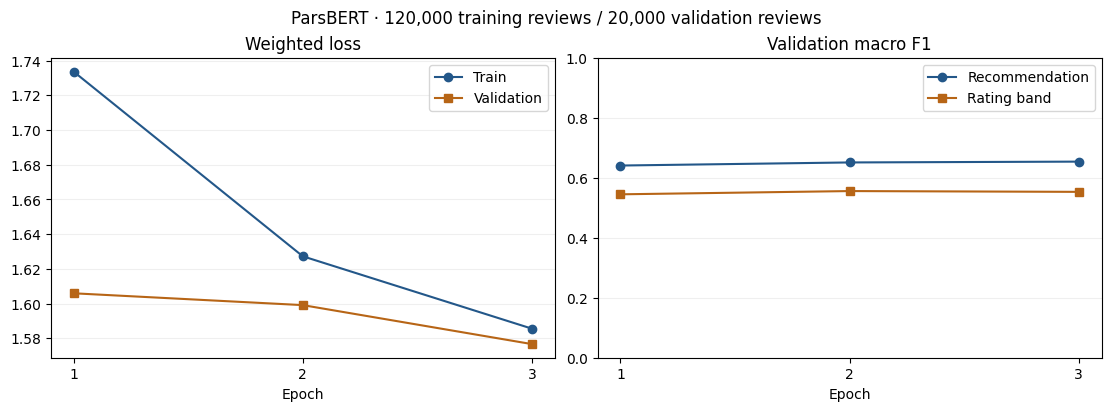

Evaluation:   0%|          | 0/38 [00:00<?, ?it/s]


recommendation_status | evaluated rows: 789,770
Accuracy: 0.8107 | Balanced accuracy: 0.7079
Macro F1: 0.6602 | TF-IDF: 0.5431 | Difference: +0.1171
                 precision  recall  f1-score   support
recommended         0.9524  0.8608    0.9043  624568.0
not_recommended     0.5815  0.7578    0.6581   75961.0
no_idea             0.3570  0.5052    0.4183   89241.0

rating_band | evaluated rows: 925,196
Accuracy: 0.6468 | Balanced accuracy: 0.5712
Macro F1: 0.5567 | TF-IDF: 0.5494 | Difference: +0.0073
        precision  recall  f1-score   support
low        0.4766  0.5111    0.4932  163553.0
medium     0.3546  0.4722    0.4050  159968.0
high       0.8185  0.7302    0.7718  601675.0
Mean absolute ordinal distance: 0.4664

Saved: parsbert_supervised_validation.json and parsbert_supervised_curves.png


In [ ]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from digikala_evaluation import evaluate_csv

project_drive = Path("/content/drive/MyDrive/digikala-project-3")
reports_dir = project_drive / "reports"
checkpoint_dir = project_drive / "artifacts" / "parsbert_supervised"
training = json.loads((reports_dir / "parsbert_supervised_training.json").read_text())
history = training["history"]
epochs = [row["epoch"] for row in history]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(epochs, [row["train"]["loss"] for row in history],
             marker="o", color="#235789", label="Train")
axes[0].plot(epochs, [row["validation"]["loss"] for row in history],
             marker="s", color="#b76516", label="Validation")
axes[0].set(title="Weighted loss", xlabel="Epoch", xticks=epochs)
axes[0].legend()

for metric, label, marker, color in [
    ("recommendation_macro_f1", "Recommendation", "o", "#235789"),
    ("rating_macro_f1", "Rating band", "s", "#b76516"),
]:
    axes[1].plot(epochs, [row["validation"][metric] for row in history],
                 marker=marker, color=color, label=label)
axes[1].set(title="Validation macro F1", xlabel="Epoch", xticks=epochs, ylim=(0, 1))
axes[1].legend()

for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.suptitle("ParsBERT · 120,000 training reviews / 20,000 validation reviews")
fig.savefig(reports_dir / "parsbert_supervised_curves.png", dpi=150)
plt.show()

splits_dir = Path("/content/digikala_splits")
manifest = json.loads((splits_dir / "split_manifest.json").read_text())
baseline = json.loads((reports_dir / "baseline_validation.json").read_text())

validation = evaluate_csv(
    model, splits_dir / "validation.csv", tokenizer, MAX_LENGTH,
    expected_rows=manifest["exported_file_rows"]["validation.csv"],
)
validation["split"] = "validation"
validation["checkpoint_epoch"] = training["best_epoch"]

for target, record in validation["heads"].items():
    reference = baseline["heads"][target]
    assert record["evaluated_rows"] == reference["evaluated_rows"], target
    metrics = record["metrics"]
    macro_f1 = metrics["macro avg"]["f1-score"]
    baseline_f1 = reference["metrics"]["macro avg"]["f1-score"]
    names = record["confusion_matrix"]["class_order"]

    print(f"\n{target} | evaluated rows: {record['evaluated_rows']:,}")
    print(f"Accuracy: {metrics['accuracy']:.4f} | Balanced accuracy: {record['balanced_accuracy']:.4f}")
    print(f"Macro F1: {macro_f1:.4f} | TF-IDF: {baseline_f1:.4f} | Difference: {macro_f1 - baseline_f1:+.4f}")
    print(pd.DataFrame(metrics).T.loc[names].round(4).to_string())
    if target == "rating_band":
        print(f"Mean absolute ordinal distance: {record['mean_absolute_ordinal_distance']:.4f}")

report_path = reports_dir / "parsbert_supervised_validation.json"
report_path.write_text(json.dumps(validation, indent=2), encoding="utf-8")
shutil.copyfile("/content/digikala_evaluation.py", checkpoint_dir / "digikala_evaluation.py")
print(f"\nSaved: {report_path.name} and parsbert_supervised_curves.png")

In [ ]:
import json
import shutil
import tarfile
from pathlib import Path

from google.colab import drive

drive.mount("/content/drive")

root = Path("/content/drive/MyDrive/digikala-project-3")
original_dir = root / "artifacts" / "parsbert_supervised"
candidate_dir = root / "artifacts" / "parsbert_supervised_500k"
report_path = root / "reports" / "parsbert_supervised_500k.json"
checkpoint_path = candidate_dir / "best.pt"

if report_path.is_file() and checkpoint_path.is_file():
    report = json.loads(report_path.read_text(encoding="utf-8"))
    assert report["settings"]["train_rows"] == 500_000
    print("500K_COMPLETE")
    print(json.dumps(report["validation"], indent=2))
    print(f"Mean macro F1: {report['selection_score']:.4f}")
else:
    required = [
        Path("/content/digikala_splits/train_supervised.csv"),
        Path("/content/digikala_splits/validation.csv"),
        Path("/content/normalize_persian.py"),
    ]
    if not all(path.is_file() for path in required):
        bundle = Path("/content/digikala_inputs.tar.gz")
        shutil.copyfile(root / bundle.name, bundle)
        with tarfile.open(bundle, "r:gz") as archive:
            archive.extractall("/content", filter="data")

    assert all(path.is_file() for path in required)
    assert (original_dir / "best.pt").is_file()
    print("READY_TO_TRAIN")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
READY_TO_TRAIN


In [ ]:
%pip -q install "transformers==5.22.1" duckdb

import json
import math
import shutil
import tarfile
from pathlib import Path
from time import perf_counter

import duckdb
import torch
from google.colab import drive
from transformers import AutoModel, AutoTokenizer

TRAIN_ROWS = 1_200_000

drive.mount("/content/drive")
root = Path("/content/drive/MyDrive/digikala-project-3")
original_dir = root / "artifacts" / "parsbert_supervised"
candidate_dir = root / "artifacts" / "parsbert_supervised_1200k"
report_path = root / "reports" / "parsbert_supervised_1200k.json"
checkpoint_path = candidate_dir / "best.pt"

original = json.loads(
    (root / "reports" / "parsbert_supervised_training.json").read_text(encoding="utf-8")
)
settings = original["settings"]
previous = next(row for row in original["history"] if row["epoch"] == original["best_epoch"])
metrics = ["recommendation_macro_f1", "rating_macro_f1"]

def train_candidate():
    if not torch.cuda.is_available():
        raise RuntimeError("Select T4 GPU in Runtime > Change runtime type.")

    splits = Path("/content/digikala_splits")
    split_names = ["train_supervised", "validation"]
    if not all((splits / f"{name}.csv").is_file() for name in split_names):
        bundle = Path("/content/digikala_inputs.tar.gz")
        shutil.copyfile(root / bundle.name, bundle)
        with tarfile.open(bundle, "r:gz") as archive:
            archive.extractall("/content", filter="data")

    for name in ["digikala_transformer.py", "digikala_training.py", "normalize_persian.py"]:
        shutil.copyfile(original_dir / name, Path("/content") / name)

    from digikala_transformer import DigikalaTransformer
    from digikala_training import make_loader, run_epoch

    checkpoint = torch.load(original_dir / "best.pt", map_location="cpu", weights_only=True)
    assert checkpoint["epoch"] == original["best_epoch"]

    tokenizer = AutoTokenizer.from_pretrained(
        str(original_dir / "tokenizer"), local_files_only=True,
    )
    encoder = AutoModel.from_pretrained(
        settings["model"], revision=settings["revision"], add_pooling_layer=False,
        use_safetensors=False, weights_only=True, trust_remote_code=False,
    )
    model = DigikalaTransformer(encoder).to("cuda")
    assert set(checkpoint["parameters"]) == {
        name for name, parameter in model.named_parameters() if parameter.requires_grad
    }
    model.load_state_dict(checkpoint["parameters"], strict=False)

    validation_rows = settings["validation_rows_for_checkpoint_selection"]
    with duckdb.connect(config={"memory_limit": "3GB", "threads": "2"}) as db:
        train_frame, validation_frame = [
            db.execute("""
                SELECT id, body, recommendation_status, rating_band
                FROM read_csv(?, header=true, all_varchar=true)
                ORDER BY substr(sha256('2026|' || id), 1, 16), id
                LIMIT ?
            """, [str(splits / f"{name}.csv"), size]).df()
            for name, size in zip(split_names, [TRAIN_ROWS, validation_rows])
        ]

    assert len(train_frame) == TRAIN_ROWS
    assert len(validation_frame) == validation_rows

    weights = tuple(
        torch.tensor(settings[key], dtype=torch.float32, device="cuda")
        for key in ["recommendation_weights", "rating_band_weights"]
    )
    head_parameters = (
        list(model.recommendation_head.parameters())
        + list(model.rating_head.parameters())
    )
    optimizer = torch.optim.AdamW([
        {"params": model.encoder.encoder.layer[-1].parameters(),
         "lr": settings["encoder_lr"]},
        {"params": head_parameters, "lr": settings["head_lr"]},
    ], weight_decay=0.01)
    scaler = torch.amp.GradScaler("cuda")

    epoch = checkpoint["epoch"] + 1
    seed = settings["seed"] + epoch
    torch.manual_seed(seed)
    max_length, batch_size = settings["max_length"], settings["batch_size"]
    train_loader = make_loader(
        train_frame, tokenizer, max_length, batch_size, shuffle=True, seed=seed,
    )
    validation_loader = make_loader(validation_frame, tokenizer, max_length, batch_size)
    del train_frame, validation_frame

    print(f"Train: {TRAIN_ROWS:,} | Validation: {validation_rows:,}", flush=True)
    started = perf_counter()
    train_metrics = run_epoch(
        model, train_loader, weights, optimizer=optimizer, scaler=scaler,
    )
    validation_metrics = run_epoch(model, validation_loader, weights)
    assert all(math.isfinite(value) for value in [train_metrics["loss"], *validation_metrics.values()])
    score = sum(validation_metrics[key] for key in metrics) / len(metrics)

    candidate_dir.mkdir(parents=True, exist_ok=True)
    temporary = checkpoint_path.with_suffix(".tmp")
    torch.save({
        "parameters": {
            name: parameter.detach().cpu()
            for name, parameter in model.named_parameters() if parameter.requires_grad
        },
        "epoch": epoch,
        "score": score,
    }, temporary)
    temporary.replace(checkpoint_path)

    report = {
        "parent_epoch": checkpoint["epoch"],
        "settings": {**settings, "train_rows": TRAIN_ROWS},
        "additional_epochs": 1,
        "optimizer_reinitialized": True,
        "train": train_metrics,
        "validation": validation_metrics,
        "selection_score": score,
        "seconds": round(perf_counter() - started, 1),
    }
    report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
    return report

if checkpoint_path.is_file() and report_path.is_file():
    report = json.loads(report_path.read_text(encoding="utf-8"))
    assert report["settings"]["train_rows"] == TRAIN_ROWS
    print("1.2M run already saved.")
else:
    report = train_candidate()

print("\nSame 20,000 validation reviews")
for key in metrics:
    before, after = previous["validation"][key], report["validation"][key]
    print(f"{key}: {before:.4f} -> {after:.4f} ({after - before:+.4f})")
print(f"Mean macro F1: {previous['selection_score']:.4f} -> {report['selection_score']:.4f}")
print(f"Saved checkpoint and report | Elapsed: {report['seconds']}s")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


config.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

... (3 outputs left out)

Train: 1,200,000 | Validation: 20,000


Train:   0%|          | 0/18750 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]


Same 20,000 validation reviews
recommendation_macro_f1: 0.6543 -> 0.6638 (+0.0095)
rating_macro_f1: 0.5534 -> 0.5718 (+0.0185)
Mean macro F1: 0.6038 -> 0.6178
Saved checkpoint and report | Elapsed: 1685.6s


In [ ]:
import json
import shutil
from pathlib import Path

import pandas as pd
import torch
from transformers import AutoModel, AutoTokenizer

root = Path("/content/drive/MyDrive/digikala-project-3")
reports = root / "reports"
original_dir = root / "artifacts" / "parsbert_supervised"
candidate_dir = root / "artifacts" / "parsbert_supervised_1200k"
splits = Path("/content/digikala_splits")

shutil.copyfile(
    original_dir / "digikala_evaluation.py",
    "/content/digikala_evaluation.py",
)

from digikala_evaluation import evaluate_csv
from digikala_transformer import DigikalaTransformer

candidate_report = json.loads(
    (reports / "parsbert_supervised_1200k.json").read_text(encoding="utf-8")
)
settings = candidate_report["settings"]
assert settings["train_rows"] == 1_200_000

tokenizer = AutoTokenizer.from_pretrained(
    str(original_dir / "tokenizer"), local_files_only=True,
)
encoder = AutoModel.from_pretrained(
    settings["model"], revision=settings["revision"], add_pooling_layer=False,
    use_safetensors=False, weights_only=True, trust_remote_code=False,
)
candidate = DigikalaTransformer(encoder).to("cuda")
checkpoint = torch.load(
    candidate_dir / "best.pt", map_location="cpu", weights_only=True,
)
assert set(checkpoint["parameters"]) == {
    name for name, parameter in candidate.named_parameters() if parameter.requires_grad
}
candidate.load_state_dict(checkpoint["parameters"], strict=False)

manifest = json.loads((splits / "split_manifest.json").read_text(encoding="utf-8"))
previous = json.loads(
    (reports / "parsbert_supervised_validation.json").read_text(encoding="utf-8")
)

results = evaluate_csv(
    candidate, splits / "validation.csv", tokenizer, settings["max_length"],
    expected_rows=manifest["exported_file_rows"]["validation.csv"],
)
results.update({
    "split": "validation",
    "checkpoint_epoch": checkpoint["epoch"],
    "continuation_training_rows": settings["train_rows"],
})

for target, record in results["heads"].items():
    reference = previous["heads"][target]
    assert record["evaluated_rows"] == reference["evaluated_rows"], target

    metrics = record["metrics"]
    before = reference["metrics"]["macro avg"]["f1-score"]
    after = metrics["macro avg"]["f1-score"]
    classes = record["confusion_matrix"]["class_order"]

    print(f"\n{target} | evaluated rows: {record['evaluated_rows']:,}")
    print(f"Accuracy: {metrics['accuracy']:.4f} | Balanced accuracy: {record['balanced_accuracy']:.4f}")
    print(f"Macro F1: {before:.4f} -> {after:.4f} ({after - before:+.4f})")
    print(pd.DataFrame(metrics).T.loc[classes].round(4).to_string())

    if target == "rating_band":
        old_distance = reference["mean_absolute_ordinal_distance"]
        new_distance = record["mean_absolute_ordinal_distance"]
        print(f"Mean absolute ordinal distance: {old_distance:.4f} -> {new_distance:.4f}")

report_path = reports / "parsbert_supervised_1200k_validation.json"
report_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"\nSaved: {report_path.name}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

Evaluation:   0%|          | 0/38 [00:00<?, ?it/s]


recommendation_status | evaluated rows: 789,770
Accuracy: 0.7974 | Balanced accuracy: 0.7298
Macro F1: 0.6602 -> 0.6696 (+0.0094)
                 precision  recall  f1-score   support
recommended         0.9635  0.8307    0.8922  624568.0
not_recommended     0.6312  0.7775    0.6967   75961.0
no_idea             0.3288  0.5811    0.4199   89241.0

rating_band | evaluated rows: 925,196
Accuracy: 0.6701 | Balanced accuracy: 0.5837
Macro F1: 0.5567 -> 0.5754 (+0.0187)
        precision  recall  f1-score   support
low        0.5213  0.5213    0.5213  163553.0
medium     0.3732  0.4646    0.4139  159968.0
high       0.8185  0.7653    0.7910  601675.0
Mean absolute ordinal distance: 0.4664 -> 0.4322

Saved: parsbert_supervised_1200k_validation.json


In [1]:
%pip -q install "transformers==5.22.1" duckdb

import hashlib
import json
import math
import shutil
import tarfile
from pathlib import Path
from time import perf_counter

import duckdb
import pandas as pd
import torch
from google.colab import drive
from transformers import AutoModel, AutoTokenizer

drive.mount("/content/drive")

TRAIN_ROWS = 3_000_000
BLOCK_ROWS = 102_400

root = Path("/content/drive/MyDrive/digikala-project-3")
original_dir = root / "artifacts" / "parsbert_supervised"
parent_dir = root / "artifacts" / "parsbert_supervised_1200k"
output_dir = root / "artifacts" / "parsbert_supervised_3000k"
reports_dir = root / "reports"
splits_dir = Path("/content/digikala_splits")

output_dir.mkdir(parents=True, exist_ok=True)
latest_path = output_dir / "latest.pt"
best_path = output_dir / "best.pt"
report_path = reports_dir / "parsbert_supervised_3000k.json"

parent_report = json.loads(
    (reports_dir / "parsbert_supervised_1200k.json").read_text(encoding="utf-8")
)
settings = parent_report["settings"]

def save_checkpoint(payload, destination):
    temporary = destination.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(destination)

def train_three_million():
    if not torch.cuda.is_available():
        raise RuntimeError("Select T4 GPU in Runtime > Change runtime type.")

    needed = ["train_supervised.csv", "validation.csv"]
    if not all((splits_dir / name).is_file() for name in needed):
        print("Restoring training files...", flush=True)
        bundle = Path("/content/digikala_inputs.tar.gz")
        shutil.copyfile(root / bundle.name, bundle)
        with tarfile.open(bundle, "r:gz") as archive:
            archive.extractall("/content", filter="data")

    for name in [
        "digikala_transformer.py",
        "digikala_training.py",
        "normalize_persian.py",
    ]:
        shutil.copyfile(original_dir / name, Path("/content") / name)

    from digikala_transformer import DigikalaTransformer
    from digikala_training import make_loader, run_epoch

    parent_path = parent_dir / "best.pt"
    with parent_path.open("rb") as file:
        parent_hash = hashlib.file_digest(file, "sha256").hexdigest()

    validation_rows = settings["validation_rows_for_checkpoint_selection"]
    seed = settings["seed"] + 5
    run_config = {
        "parent_checkpoint_sha256": parent_hash,
        "train_rows": TRAIN_ROWS,
        "validation_rows": validation_rows,
        "block_rows": BLOCK_ROWS,
        "shuffle_seed": seed,
        "sample_rule": (
            "First 3000000 supervised rows ordered by the first 16 hex digits "
            "of SHA-256('2026|' + id), then id"
        ),
        "parent_settings": settings,
    }

    print("Selecting training and validation rows...", flush=True)
    with duckdb.connect(config={"memory_limit": "3GB", "threads": "2"}) as db:
        train_frame, validation_frame = [
            db.execute("""
                SELECT id, body, recommendation_status, rating_band
                FROM read_csv(?, header=true, all_varchar=true)
                ORDER BY substr(sha256('2026|' || id), 1, 16), id
                LIMIT ?
            """, [str(splits_dir / name), size]).df()
            for name, size in [
                ("train_supervised.csv", TRAIN_ROWS),
                ("validation.csv", validation_rows),
            ]
        ]

    assert len(train_frame) == TRAIN_ROWS
    assert len(validation_frame) == validation_rows

    # Shuffle the entire selected training set before dividing it into blocks.
    train_frame = train_frame.sample(frac=1, random_state=seed).reset_index(drop=True)

    tokenizer = AutoTokenizer.from_pretrained(
        str(original_dir / "tokenizer"), local_files_only=True,
    )
    encoder = AutoModel.from_pretrained(
        settings["model"],
        revision=settings["revision"],
        add_pooling_layer=False,
        use_safetensors=False,
        weights_only=True,
        trust_remote_code=False,
    )
    model = DigikalaTransformer(encoder).to("cuda")

    resuming = latest_path.is_file()
    state = torch.load(
        latest_path if resuming else parent_path,
        map_location="cpu",
        weights_only=True,
    )
    if resuming:
        assert state["run_config"] == run_config, "Saved run settings differ."

    trainable_names = {
        name for name, parameter in model.named_parameters()
        if parameter.requires_grad
    }
    assert set(state["parameters"]) == trainable_names
    model.load_state_dict(state["parameters"], strict=False)

    weights = tuple(
        torch.tensor(settings[key], dtype=torch.float32, device="cuda")
        for key in ["recommendation_weights", "rating_band_weights"]
    )
    optimizer = torch.optim.AdamW([
        {
            "params": model.encoder.encoder.layer[-1].parameters(),
            "lr": settings["encoder_lr"],
        },
        {
            "params": list(model.recommendation_head.parameters())
                      + list(model.rating_head.parameters()),
            "lr": settings["head_lr"],
        },
    ], weight_decay=0.01)
    scaler = torch.amp.GradScaler("cuda")

    completed_rows = 0
    blocks = []
    if resuming:
        optimizer.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        completed_rows = state["completed_rows"]
        blocks = state["blocks"]

    assert 0 <= completed_rows <= TRAIN_ROWS
    assert completed_rows == TRAIN_ROWS or completed_rows % BLOCK_ROWS == 0
    del state

    max_length = settings["max_length"]
    batch_size = settings["batch_size"]
    assert BLOCK_ROWS % batch_size == 0

    print(
        f"GPU: {torch.cuda.get_device_name(0)}\n"
        f"Train: {TRAIN_ROWS:,} | Validation: {validation_rows:,}\n"
        f"Already completed: {completed_rows:,}",
        flush=True,
    )

    for start in range(completed_rows, TRAIN_ROWS, BLOCK_ROWS):
        end = min(start + BLOCK_ROWS, TRAIN_ROWS)
        block_index = start // BLOCK_ROWS

        # Each block has its own fixed random seed for resumable dropout.
        torch.manual_seed(seed + block_index)
        loader = make_loader(
            train_frame.iloc[start:end],
            tokenizer, max_length, batch_size,
            shuffle=False, seed=seed + block_index,
        )

        print(f"\nTraining rows {start + 1:,}–{end:,}", flush=True)
        started = perf_counter()
        metrics = run_epoch(
            model, loader, weights, optimizer=optimizer, scaler=scaler,
        )
        assert math.isfinite(metrics["loss"])

        blocks.append({
            "rows": end - start,
            "batches": len(loader),
            "loss": metrics["loss"],
            "seconds": round(perf_counter() - started, 1),
        })
        del loader

        save_checkpoint({
            "run_config": run_config,
            "completed_rows": end,
            "blocks": blocks,
            "parameters": {
                name: parameter.detach().cpu()
                for name, parameter in model.named_parameters()
                if parameter.requires_grad
            },
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
        }, latest_path)

        print(f"Saved progress: {end:,} / {TRAIN_ROWS:,}", flush=True)

    del train_frame

    validation_loader = make_loader(
        validation_frame, tokenizer, max_length, batch_size,
    )
    validation_metrics = run_epoch(model, validation_loader, weights)
    assert all(math.isfinite(value) for value in validation_metrics.values())

    score = (
        validation_metrics["recommendation_macro_f1"]
        + validation_metrics["rating_macro_f1"]
    ) / 2
    epoch = parent_report["parent_epoch"] + parent_report["additional_epochs"] + 1

    save_checkpoint({
        "parameters": {
            name: parameter.detach().cpu()
            for name, parameter in model.named_parameters()
            if parameter.requires_grad
        },
        "epoch": epoch,
        "score": score,
        "parent_checkpoint_sha256": parent_hash,
    }, best_path)

    report = {
        "settings": {**settings, "train_rows": TRAIN_ROWS},
        "run_config": run_config,
        "parent_epoch": epoch - 1,
        "additional_epochs": 1,
        "optimizer_reinitialized_at_start": True,
        "class_weights_source": "Inherited from the supervised parent model",
        "blocks": blocks,
        "train": {
            "loss": sum(block["loss"] * block["batches"] for block in blocks)
                    / sum(block["batches"] for block in blocks),
        },
        "validation": validation_metrics,
        "selection_score": score,
        "training_seconds": sum(block["seconds"] for block in blocks),
        "environment": {
            "torch": str(torch.__version__),
            "pandas": pd.__version__,
        },
    }

    tokenizer.save_pretrained(output_dir / "tokenizer")
    for name in [
        "digikala_transformer.py",
        "digikala_training.py",
        "digikala_evaluation.py",
        "normalize_persian.py",
    ]:
        shutil.copyfile(original_dir / name, output_dir / name)

    temporary = report_path.with_suffix(".tmp")
    temporary.write_text(json.dumps(report, indent=2), encoding="utf-8")
    temporary.replace(report_path)
    return report

if best_path.is_file() and report_path.is_file():
    result = json.loads(report_path.read_text(encoding="utf-8"))
    assert result["settings"]["train_rows"] == TRAIN_ROWS
    print("Completed 3M run already saved.")
else:
    result = train_three_million()

print("\nSame 20,000 validation reviews")
for metric in ["recommendation_macro_f1", "rating_macro_f1"]:
    before = parent_report["validation"][metric]
    after = result["validation"][metric]
    print(f"{metric}: {before:.4f} -> {after:.4f} ({after - before:+.4f})")

print(
    f"Mean macro F1: {parent_report['selection_score']:.4f}"
    f" -> {result['selection_score']:.4f}"
)
print("Saved: parsbert_supervised_3000k checkpoint and training report.")

Mounted at /content/drive
Restoring training files...
Selecting training and validation rows...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

config.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (63 outputs left out)

Train:   0%|          | 0/475 [00:00<?, ?it/s]

Saved progress: 3,000,000 / 3,000,000


Validation:   0%|          | 0/313 [00:00<?, ?it/s]


Same 20,000 validation reviews
recommendation_macro_f1: 0.6638 -> 0.6765 (+0.0128)
rating_macro_f1: 0.5718 -> 0.5832 (+0.0113)
Mean macro F1: 0.6178 -> 0.6299
Saved: parsbert_supervised_3000k checkpoint and training report.


In [2]:
import json
import shutil
from pathlib import Path

import pandas as pd
import torch
from transformers import AutoModel, AutoTokenizer

if not torch.cuda.is_available():
    raise RuntimeError("Select T4 GPU in Runtime > Change runtime type.")

root = Path("/content/drive/MyDrive/digikala-project-3")
reports_dir = root / "reports"
model_dir = root / "artifacts" / "parsbert_supervised_3000k"
splits_dir = Path("/content/digikala_splits")

for name in [
    "digikala_transformer.py",
    "digikala_training.py",
    "digikala_evaluation.py",
    "normalize_persian.py",
]:
    shutil.copyfile(model_dir / name, Path("/content") / name)

from digikala_transformer import DigikalaTransformer
from digikala_evaluation import evaluate_csv

training = json.loads(
    (reports_dir / "parsbert_supervised_3000k.json").read_text(encoding="utf-8")
)
previous = json.loads(
    (reports_dir / "parsbert_supervised_1200k_validation.json").read_text(
        encoding="utf-8"
    )
)
settings = training["settings"]
assert settings["train_rows"] == 3_000_000

tokenizer = AutoTokenizer.from_pretrained(
    str(model_dir / "tokenizer"),
    local_files_only=True,
)
encoder = AutoModel.from_pretrained(
    settings["model"],
    revision=settings["revision"],
    add_pooling_layer=False,
    use_safetensors=False,
    weights_only=True,
    trust_remote_code=False,
)
model = DigikalaTransformer(encoder).to("cuda")

checkpoint = torch.load(
    model_dir / "best.pt",
    map_location="cpu",
    weights_only=True,
)
assert set(checkpoint["parameters"]) == {
    name for name, parameter in model.named_parameters()
    if parameter.requires_grad
}
model.load_state_dict(checkpoint["parameters"], strict=False)
model.eval()

print(
    f"Evaluating 3M model on {previous['total_rows']:,} validation reviews...",
    flush=True,
)
results = evaluate_csv(
    model,
    splits_dir / "validation.csv",
    tokenizer,
    settings["max_length"],
    expected_rows=previous["total_rows"],
)
results.update({
    "split": "validation",
    "checkpoint_epoch": checkpoint["epoch"],
    "continuation_training_rows": 3_000_000,
    "checkpoint_directory": model_dir.name,
})

# Save the evaluation before printing the comparison.
report_path = reports_dir / "parsbert_supervised_3000k_validation.json"
temporary = report_path.with_suffix(".tmp")
temporary.write_text(json.dumps(results, indent=2), encoding="utf-8")
temporary.replace(report_path)

for target, record in results["heads"].items():
    reference = previous["heads"][target]
    assert record["evaluated_rows"] == reference["evaluated_rows"]

    old_metrics = reference["metrics"]
    new_metrics = record["metrics"]
    old_f1 = old_metrics["macro avg"]["f1-score"]
    new_f1 = new_metrics["macro avg"]["f1-score"]
    classes = record["confusion_matrix"]["class_order"]

    print(f"\n{target} | evaluated rows: {record['evaluated_rows']:,}")
    print(
        f"Accuracy: {old_metrics['accuracy']:.4f}"
        f" -> {new_metrics['accuracy']:.4f}"
    )
    print(
        f"Balanced accuracy: {reference['balanced_accuracy']:.4f}"
        f" -> {record['balanced_accuracy']:.4f}"
    )
    print(f"Macro F1: {old_f1:.4f} -> {new_f1:.4f} ({new_f1 - old_f1:+.4f})")
    print(
        pd.DataFrame(new_metrics).T
        .loc[classes + ["macro avg"]]
        .round(4).to_string()
    )

    if target == "rating_band":
        old_distance = reference["mean_absolute_ordinal_distance"]
        new_distance = record["mean_absolute_ordinal_distance"]
        print(
            f"Mean absolute ordinal distance:"
            f" {old_distance:.4f} -> {new_distance:.4f}"
        )

print(f"\nSaved: {report_path.name}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

Evaluating 3M model on 925,197 validation reviews...


Evaluation:   0%|          | 0/38 [00:00<?, ?it/s]


recommendation_status | evaluated rows: 789,770
Accuracy: 0.7974 -> 0.8117
Balanced accuracy: 0.7298 -> 0.7379
Macro F1: 0.6696 -> 0.6824 (+0.0128)
                 precision  recall  f1-score   support
recommended         0.9636  0.8480    0.9021  624568.0
not_recommended     0.6448  0.7893    0.7098   75961.0
no_idea             0.3496  0.5764    0.4353   89241.0
macro avg           0.6527  0.7379    0.6824  789770.0

rating_band | evaluated rows: 925,196
Accuracy: 0.6701 -> 0.6789
Balanced accuracy: 0.5837 -> 0.5892
Macro F1: 0.5754 -> 0.5846 (+0.0092)
           precision  recall  f1-score   support
low           0.5729  0.4853    0.5255  163553.0
medium        0.3752  0.5044    0.4303  159968.0
high          0.8189  0.7780    0.7979  601675.0
macro avg     0.5890  0.5892    0.5846  925196.0
Mean absolute ordinal distance: 0.4322 -> 0.4112

Saved: parsbert_supervised_3000k_validation.json


In [3]:
import hashlib
import json
from pathlib import Path

import pandas as pd
import torch

from digikala_evaluation import evaluate_csv

root = Path("/content/drive/MyDrive/digikala-project-3")
reports_dir = root / "reports"
model_dir = root / "artifacts" / "parsbert_supervised_3000k"
splits_dir = Path("/content/digikala_splits")
checkpoint_path = model_dir / "best.pt"
report_path = reports_dir / "parsbert_supervised_3000k_test.json"

with checkpoint_path.open("rb") as file:
    checkpoint_hash = hashlib.file_digest(file, "sha256").hexdigest()

manifest = json.loads(
    (splits_dir / "split_manifest.json").read_text(encoding="utf-8")
)
training = json.loads(
    (reports_dir / "parsbert_supervised_3000k.json").read_text(encoding="utf-8")
)
expected_rows = manifest["exported_file_rows"]["test.csv"]

if report_path.is_file():
    results = json.loads(report_path.read_text(encoding="utf-8"))
    assert results["checkpoint_sha256"] == checkpoint_hash
    assert results["total_rows"] == expected_rows
    print("Saved test evaluation loaded.")
else:
    if not torch.cuda.is_available():
        raise RuntimeError("Select T4 GPU in Runtime > Change runtime type.")

    # Use the model and tokenizer from the preceding validation cell.
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True,
    )
    assert set(checkpoint["parameters"]) == {
        name for name, parameter in model.named_parameters()
        if parameter.requires_grad
    }
    model.load_state_dict(checkpoint["parameters"], strict=False)
    model.eval()

    print(f"Evaluating {expected_rows:,} test reviews...", flush=True)
    results = evaluate_csv(
        model,
        splits_dir / "test.csv",
        tokenizer,
        training["settings"]["max_length"],
        expected_rows=expected_rows,
    )
    results.update({
        "split": "test",
        "checkpoint_directory": model_dir.name,
        "checkpoint_sha256": checkpoint_hash,
        "checkpoint_epoch": checkpoint["epoch"],
        "continuation_training_rows": 3_000_000,
    })

    temporary = report_path.with_suffix(".tmp")
    temporary.write_text(json.dumps(results, indent=2), encoding="utf-8")
    temporary.replace(report_path)

for target, record in results["heads"].items():
    metrics = record["metrics"]
    classes = record["confusion_matrix"]["class_order"]

    print(f"\nTEST — {target}")
    print(f"Evaluated rows: {record['evaluated_rows']:,}")
    print(f"Accuracy: {metrics['accuracy']:.4f}")
    print(f"Macro F1: {metrics['macro avg']['f1-score']:.4f}")
    print(f"Balanced accuracy: {record['balanced_accuracy']:.4f}")
    print(
        pd.DataFrame(metrics).T
        .loc[classes + ["macro avg"]]
        .round(4).to_string()
    )

    print("\nConfusion matrix — rows: actual, columns: predicted")
    print(pd.DataFrame(
        record["confusion_matrix"]["counts"],
        index=classes,
        columns=classes,
    ).to_string())

    if target == "rating_band":
        print(
            "Mean absolute ordinal distance: "
            f"{record['mean_absolute_ordinal_distance']:.4f}"
        )

print(f"\nSaved: {report_path.name}")

Evaluating 919,675 test reviews...


Evaluation:   0%|          | 0/37 [00:00<?, ?it/s]


TEST — recommendation_status
Evaluated rows: 785,776
Accuracy: 0.8134
Macro F1: 0.6821
Balanced accuracy: 0.7373
                 precision  recall  f1-score   support
recommended         0.9637  0.8504    0.9035  623237.0
not_recommended     0.6437  0.7865    0.7080   74456.0
no_idea             0.3496  0.5749    0.4348   88083.0
macro avg           0.6523  0.7373    0.6821  785776.0

Confusion matrix — rows: actual, columns: predicted
                 recommended  not_recommended  no_idea
recommended           529979            12296    80962
not_recommended         2633            58559    13264
no_idea                17321            20121    50641

TEST — rating_band
Evaluated rows: 919,673
Accuracy: 0.6799
Macro F1: 0.5832
Balanced accuracy: 0.5880
           precision  recall  f1-score   support
low           0.5684  0.4820    0.5216  161005.0
medium        0.3735  0.5029    0.4286  157505.0
high          0.8203  0.7792    0.7992  601163.0
macro avg     0.5874  0.5880    0.5832

In [4]:
import json
from math import ceil
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from tqdm.auto import tqdm

from normalize_persian import normalize_text

root = Path("/content/drive/MyDrive/digikala-project-3")
artifacts_dir = root / "artifacts"
reports_dir = root / "reports"
test_path = Path("/content/digikala_splits/test.csv")

transformer_results = json.loads(
    (reports_dir / "parsbert_supervised_3000k_test.json").read_text(
        encoding="utf-8"
    )
)
expected_rows = transformer_results["total_rows"]

vectorizer = joblib.load(artifacts_dir / "tfidf_vectorizer.joblib")
bundles = {
    target: joblib.load(artifacts_dir / f"tfidf_{target}.joblib")
    for target in ["recommendation_status", "rating_band"]
}
encodings = {
    target: {
        **{name: code for code, name in bundle["class_names"].items()},
        "": -1,
    }
    for target, bundle in bundles.items()
}

actual = {target: [] for target in bundles}
predicted = {target: [] for target in bundles}
total_rows = 0
chunk_size = 50_000
started = perf_counter()

chunks = pd.read_csv(
    test_path,
    chunksize=chunk_size,
    dtype=str,
    keep_default_na=False,
)

for chunk in tqdm(
    chunks,
    total=ceil(expected_rows / chunk_size),
    desc="TF-IDF test",
):
    total_rows += len(chunk)
    features = vectorizer.transform(
        normalize_text(text) for text in chunk["body"]
    )

    for target, bundle in bundles.items():
        encoded = chunk[target].map(encodings[target])
        if encoded.isna().any():
            raise ValueError(f"Unexpected label in {target}")

        y = encoded.to_numpy(dtype=np.int8)
        valid = y >= 0
        actual[target].append(y[valid])
        if valid.any():
            predicted[target].append(
                bundle["model"].predict(features[valid])
            )

assert total_rows == expected_rows

results = {
    "split": "test",
    "model": "TF-IDF + Logistic Regression",
    "total_rows": total_rows,
    "evaluation_seconds": round(perf_counter() - started, 1),
    "heads": {},
}

for target, bundle in bundles.items():
    y_true = np.concatenate(actual[target])
    y_pred = np.concatenate(predicted[target])
    codes = sorted(bundle["class_names"])
    names = [bundle["class_names"][code] for code in codes]

    assert len(y_true) == transformer_results["heads"][target]["evaluated_rows"]

    metrics = classification_report(
        y_true, y_pred,
        labels=codes,
        target_names=names,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(y_true, y_pred, labels=codes)

    record = {
        "evaluated_rows": len(y_true),
        "missing_target_rows": total_rows - len(y_true),
        "metrics": metrics,
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "confusion_matrix": {
            "class_order": names,
            "counts": matrix.tolist(),
        },
    }
    if target == "rating_band":
        record["mean_absolute_ordinal_distance"] = float(
            np.abs(y_true - y_pred).mean()
        )

    results["heads"][target] = record

report_path = reports_dir / "baseline_test.json"
temporary = report_path.with_suffix(".tmp")
temporary.write_text(json.dumps(results, indent=2), encoding="utf-8")
temporary.replace(report_path)

for target, record in results["heads"].items():
    metrics = record["metrics"]
    classes = record["confusion_matrix"]["class_order"]
    transformer = transformer_results["heads"][target]
    baseline_f1 = metrics["macro avg"]["f1-score"]
    transformer_f1 = transformer["metrics"]["macro avg"]["f1-score"]

    print(f"\nTEST — {target}")
    print(f"TF-IDF accuracy: {metrics['accuracy']:.4f}")
    print(f"TF-IDF balanced accuracy: {record['balanced_accuracy']:.4f}")
    print(
        f"Macro F1 — TF-IDF: {baseline_f1:.4f}"
        f" | ParsBERT: {transformer_f1:.4f}"
        f" | Difference: {transformer_f1 - baseline_f1:+.4f}"
    )
    print(
        pd.DataFrame(metrics).T
        .loc[classes + ["macro avg"]]
        .round(4).to_string()
    )
    if target == "rating_band":
        print(
            "TF-IDF mean absolute ordinal distance: "
            f"{record['mean_absolute_ordinal_distance']:.4f}"
        )

print(f"\nSaved: {report_path.name}")

TF-IDF test:   0%|          | 0/19 [00:00<?, ?it/s]


TEST — recommendation_status
TF-IDF accuracy: 0.8116
TF-IDF balanced accuracy: 0.6279
Macro F1 — TF-IDF: 0.5445 | ParsBERT: 0.6821 | Difference: +0.1376
                 precision  recall  f1-score   support
recommended         0.9262  0.9042    0.9151  623237.0
not_recommended     0.4132  0.8868    0.5638   74456.0
no_idea             0.4645  0.0927    0.1545   88083.0
macro avg           0.6013  0.6279    0.5445  785776.0

TEST — rating_band
TF-IDF accuracy: 0.6330
TF-IDF balanced accuracy: 0.5685
Macro F1 — TF-IDF: 0.5480 | ParsBERT: 0.5832 | Difference: +0.0351
           precision  recall  f1-score   support
low           0.4573  0.5133    0.4837  161005.0
medium        0.3417  0.4894    0.4024  157505.0
high          0.8228  0.7026    0.7580  601163.0
macro avg     0.5406  0.5685    0.5480  919673.0
TF-IDF mean absolute ordinal distance: 0.4851

Saved: baseline_test.json
